# Hoeffding's covariance identity

*Independence is a pointwise equality of distribution functions; uncorrelatedness is the same equality, integrated*

**Probability Notes No. 00** · Omid Shams Solari, Ph.D. · 8 November 2026

[PDF (A4)](pdf/pn-00-hoeffding.pdf) · [PDF (screen)](pdf/pn-00-hoeffding-screen.pdf) · [Article](article.md) · [LaTeX source](main.tex)

> **TL;DR.** Two random variables are independent exactly when their joint distribution function factorises into the product of its marginals. Hoeffding (1940) showed that their covariance is the integral of the difference between the two. Independence requires that difference to vanish everywhere; zero covariance requires only that its integral vanish.

## Result

> **Theorem 1 (Hoeffding, 1940).** Under Assumption A1, $D$ is Lebesgue integrable on $\mathbb{R}^2$ and
>
> $$
> \operatorname{Cov}(X,Y)=\iint_{\mathbb{R}^2}\big[F_{X,Y}(x,y)-F_X(x)F_Y(y)\big]\mathrm{d}x\mathrm{d}y . \tag{1}
> $$

**Remark 2.** Equivalently,

$$
\operatorname{Cov}(X,Y)=\iint_{\mathbb{R}^2}\big[\mathbb{P}(X>x,Y>y)-\bar F_X(x)\bar F_Y(y)\big]\mathrm{d}x\mathrm{d}y,
$$

since by inclusion–exclusion $\mathbb{P}(X>x,Y>y)-\bar F_X(x)\bar F_Y(y)=D(x,y)$ pointwise.

## Numerical check

The cells below are `code/check.py`, split at its numbered sections; together they print every number in this table.

Rows 1 to 3 integrate $D$ by trapezoidal quadrature on a grid; row 4 integrates the step function $D$ exactly in rational arithmetic.

| Case                                                                     |       Exact        |  Numerical  |
|:-------------------------------------------------------------------------|:------------------:|:-----------:|
| Normal, unit variances, $\rho=\tfrac12$: $\iint D\mathrm{d}x\mathrm{d}y$ |       $0.5$        | $0.500000$  |
| Same $D$: $12\iint D\mathrm{d}F_X\mathrm{d}F_Y$, i.e. (5)                | $0.4826^{\dagger}$ |  $0.4826$   |
| $X=Y\sim\mathrm{Exp}(1)$: $\iint D$, i.e. (4)                            |        $1$         | $0.999992$  |
| Worked example: $\iint D$                                                |        $0$         | $0$ (exact) |

<sup>$\dagger$</sup>From the closed form $\tfrac6\pi\arcsin(\rho/2)$ (not proved here; see Kruskal, 1958 \[8\]). Rows 1 and 2 integrate the same $D$, against $\mathrm{d}x\mathrm{d}y$ and against $\mathrm{d}F_X\mathrm{d}F_Y$ respectively (substitute $s=F_X(x)$, $t=F_Y(y)$ in (5)); only the measure differs.

### Setup

In [1]:
"""Probability Notes No. 00: numerical check.

Prints every number in the PDF's check table.
Requires Python >= 3.8, NumPy >= 1.20 and
SciPy >= 1.6 (for scipy.integrate.trapezoid).
Tested with Python 3.13, NumPy 2.5, SciPy 1.18.
Run: python3 check.py
"""
from fractions import Fraction as Q
import numpy as np
from scipy.integrate import trapezoid
from scipy.stats import norm, multivariate_normal

def trapz2(d, x, y):
    return trapezoid(trapezoid(d, x, axis=1), y)

### 1. Bivariate normal, rho = 0.5: integral of D = rho.

In [2]:
# 1. Bivariate normal, rho = 0.5: integral of D = rho.
rho = 0.5
g = np.linspace(-7.0, 7.0, 281)
x, y = np.meshgrid(g, g)
pts = np.column_stack([x.ravel(), y.ravel()])
cov = [[1, rho], [rho, 1]]
mvn = multivariate_normal([0, 0], cov)
d = mvn.cdf(pts).reshape(x.shape)
d -= norm.cdf(x) * norm.cdf(y)
print(f"Gaussian cov:  {trapz2(d, g, g):.6f}")

Gaussian cov:  0.500000


### 2. Same D, measure dF_X dF_Y: rank correlation.

In [3]:
# 2. Same D, measure dF_X dF_Y: rank correlation.
w = norm.pdf(x) * norm.pdf(y)
rs = 12 * trapz2(d * w, g, g)
print(f"Rank corr:     {rs:.4f}")
print(f"Closed form:   {6/np.pi*np.arcsin(rho/2):.4f}")

Rank corr:     0.4826
Closed form:   0.4826


### 3. X = Y ~ Exp(1): integral of D = Var(X) = 1.

In [4]:
# 3. X = Y ~ Exp(1): integral of D = Var(X) = 1.
t = np.linspace(0.0, 40.0, 4001)
fx, fy = np.meshgrid(1 - np.exp(-t), 1 - np.exp(-t))
d = np.minimum(fx, fy) - fx * fy
print(f"Exp(1) var:    {trapz2(d, t, t):.6f}")

Exp(1) var:    0.999992


### 4. X ~ Unif{-1,0,1}, Y = X^2: D is a step function; integrate it exactly on unit cells.

In [5]:
# 4. X ~ Unif{-1,0,1}, Y = X^2: D is a step
# function; integrate it exactly on unit cells.
px = {-1: Q(1, 3), 0: Q(1, 3), 1: Q(1, 3)}
def D(u, v):
    fxy = sum(p for k, p in px.items()
              if k <= u and k * k <= v)
    fx = sum(p for k, p in px.items() if k <= u)
    fy = sum(p for k, p in px.items() if k * k <= v)
    return fxy - fx * fy
cells = [(u + Q(1, 2), v + Q(1, 2))
         for u in range(-2, 2) for v in range(-1, 2)]
tot = sum(D(u, v) for u, v in cells)
mx = max(abs(D(u, v)) for u, v in cells)
print(f"Example: int D = {tot}, sup|D| = {mx}")

Example: int D = 0, sup|D| = 1/9


## Figures

`code/figures.py`: matplotlib versions of the PDF's figures.

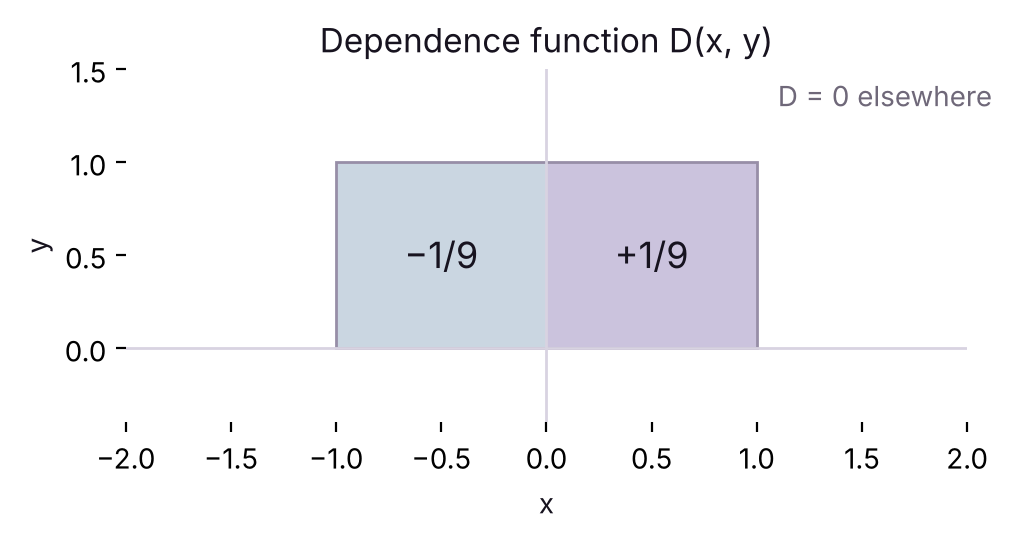

In [6]:
"""Probability Notes No. 00: figures (matplotlib).

Runs in the notebook after check.py, in the same namespace.
Figure 1: the dependence function D(x, y) for
X ~ Unif{-1, 0, 1}, Y = X^2.
"""
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

INK, MUTED = "#17131F", "#6F6879"
NEG, POS = "#2E5C8A", "#32127A"

fig, ax = plt.subplots(figsize=(5.2, 2.8))
for x0, val, col in [(-1, "−1/9", NEG), (0, "+1/9", POS)]:
    ax.add_patch(Rectangle((x0, 0), 1, 1, color=col,
                           alpha=0.25, lw=0))
    ax.text(x0 + 0.5, 0.5, val, ha="center",
            va="center", color=INK, fontsize=13)
ax.add_patch(Rectangle((-1, 0), 2, 1, fill=False,
                       ec="#978EA7"))
ax.axhline(0, color="#D8D3E1", lw=1)
ax.axvline(0, color="#D8D3E1", lw=1)
ax.set_xlim(-2, 2)
ax.set_ylim(-0.4, 1.5)
ax.set_xlabel("x", color=INK)
ax.set_ylabel("y", color=INK)
ax.text(1.1, 1.3, "D = 0 elsewhere", color=MUTED)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Dependence function D(x, y)", color=INK)
plt.tight_layout()
plt.show()